In [20]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

# Dataset paths
train_dir = '/content/train_and_validation'
val_dir = '/content/train_and_validation'

# Image preprocessing
train_datagen = ImageDataGenerator(rescale=1.0/255)
val_datagen = ImageDataGenerator(rescale=1.0/255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

# Define CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(train_generator.num_classes, activation='softmax')  # Change to train_generator.num_classes
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

# Save the model
model.save('resin_classifier.h5')

Found 685 images belonging to 8 classes.
Found 685 images belonging to 8 classes.


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


22/22 ━━━━━━━━━━━━━━━━━━━━ 97s 4s/step - accuracy: 0.1610 - loss: 5.3275 - val_accuracy: 0.2788 - val_loss: 1.9222
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 130s 4s/step - accuracy: 0.2329 - loss: 1.9798 - val_accuracy: 0.2876 - val_loss: 1.8390
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 143s 4s/step - accuracy: 0.3086 - loss: 1.8692 - val_accuracy: 0.3650 - val_loss: 1.7927
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 139s 4s/step - accuracy: 0.3463 - loss: 1.7946 - val_accuracy: 0.5051 - val_loss: 1.5845
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.4278 - loss: 1.6211 - val_accuracy: 0.5825 - val_loss: 1.3032
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 143s 4s/step - accuracy: 0.5237 - loss: 1.3748 - val_accuracy: 0.7095 - val_loss: 1.0822
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 81s 4s/step - accuracy: 0.5924 - loss: 1.1862 - val_accuracy: 0.7416 - val_loss: 0.9725
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.6375 - loss: 1.0556 - val_accuracy: 0.8161 - val_loss: 0.7014

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


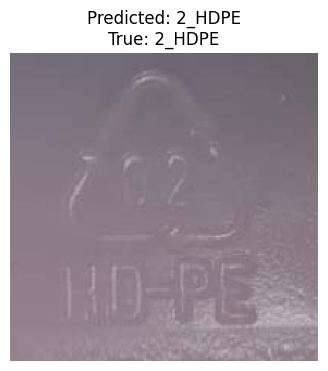

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


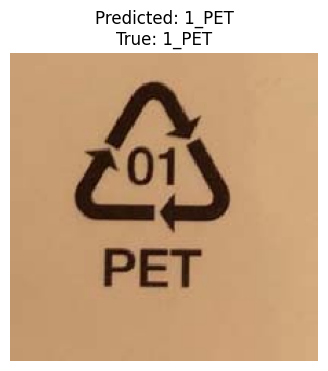

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


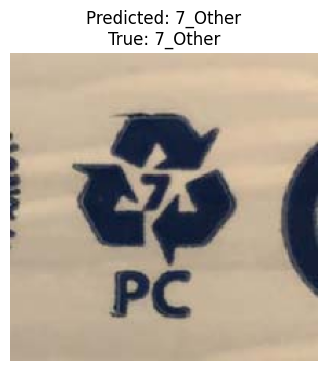

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


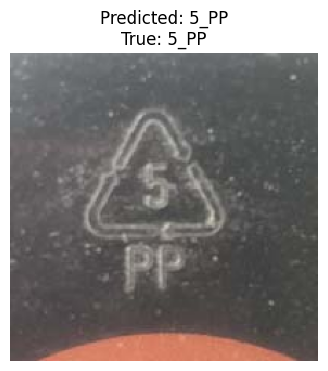

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


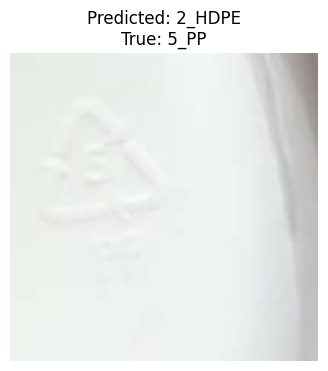

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import img_to_array, load_img

# Load the saved model
model = tf.keras.models.load_model('resin_classifier.h5')

# Define class labels
class_labels = list(train_generator.class_indices.keys())

def visualize_predictions(generator, model, class_labels, num_images=5):
    """
    Visualize predictions for a few images from the dataset.
    """
    for i in range(num_images):
        # Get a batch of images and labels
        img_batch, label_batch = next(generator)
        img = img_batch[0]
        label = label_batch[0]

        # Predict the class
        prediction = model.predict(np.expand_dims(img, axis=0))
        predicted_class_index = np.argmax(prediction)
        predicted_label = class_labels[predicted_class_index]
        true_class_index = np.argmax(label)
        true_label = class_labels[true_class_index]

        # Plot the image
        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Predicted: {predicted_label}\nTrue: {true_label}")
        plt.show()

# Visualize predictions for training images
visualize_predictions(train_generator, model, class_labels)


In [28]:
import os
import numpy as np
import cv2
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import img_to_array

# Path to the directory containing the dataset
image_dir = '/content/train_and_validation'

# Load the MNIST model
mnist_model = load_model('mnist_digit_model.h5')

# Define a function to preprocess images
def preprocess_image(image_path):
    # Load the image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    # Resize to 28x28
    img = cv2.resize(img, (28, 28))
    # Normalize pixel values (0 to 1 range)
    img = img / 255.0
    # Add channel dimension for compatibility with the model
    img = np.expand_dims(img, axis=-1)
    return img

# Prepare a batch of images and their filenames
image_batch = []
file_names = []

for root, _, files in os.walk(image_dir):
    for file in files:
        if file.endswith(('.png', '.jpg', '.jpeg')):
            file_path = os.path.join(root, file)
            image_batch.append(preprocess_image(file_path))
            file_names.append(file)

# Convert to a NumPy array
image_batch = np.array(image_batch)

# Predict digit classes
predictions = mnist_model.predict(image_batch)
predicted_classes = np.argmax(predictions, axis=1)


22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


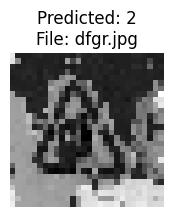

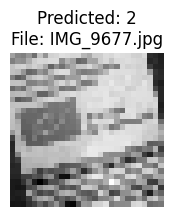

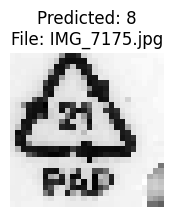

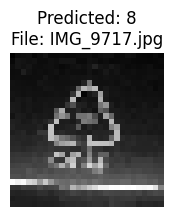

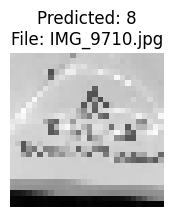

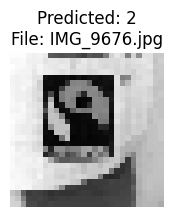

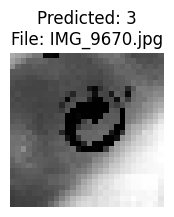

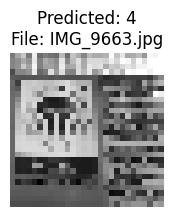

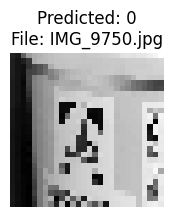

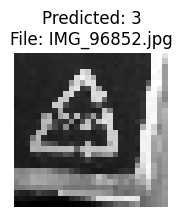

In [30]:
import matplotlib.pyplot as plt

# Visualize a few predictions
def visualize_predictions(image_batch, predicted_classes, file_names, num_images=10):
    for i in range(min(num_images, len(image_batch))):
        plt.figure(figsize=(2, 2))
        plt.imshow(image_batch[i].squeeze(), cmap='gray')
        plt.title(f"Predicted: {predicted_classes[i]}\nFile: {file_names[i]}")
        plt.axis('off')
        plt.show()

# Show predictions for a few images
visualize_predictions(image_batch, predicted_classes, file_names)


In [31]:
import pandas as pd

# Save predictions to a CSV file
results = pd.DataFrame({
    'File Name': file_names,
    'Predicted Digit': predicted_classes
})
results.to_csv('mnist_predictions.csv', index=False)
print("Predictions saved to mnist_predictions.csv")


Predictions saved to mnist_predictions.csv


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 793ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 729ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 723ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 732ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 709ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 723ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 739ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 730ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 706ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 725ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 714ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 713ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 965ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 904ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step


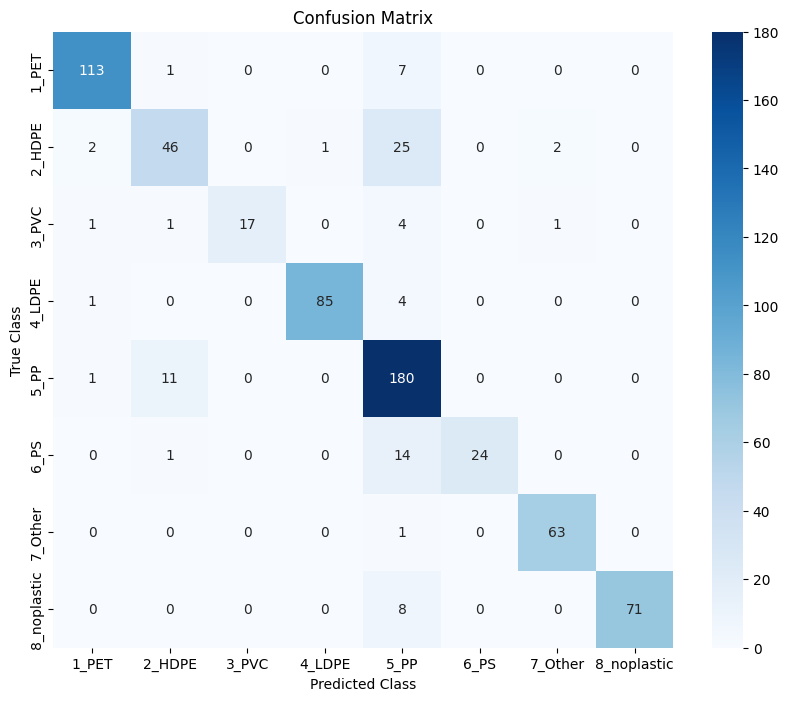

Classification Report:
              precision    recall  f1-score   support

       1_PET       0.96      0.93      0.95       121
      2_HDPE       0.77      0.61      0.68        76
       3_PVC       1.00      0.71      0.83        24
      4_LDPE       0.99      0.94      0.97        90
        5_PP       0.74      0.94      0.83       192
        6_PS       1.00      0.62      0.76        39
     7_Other       0.95      0.98      0.97        64
 8_noplastic       1.00      0.90      0.95        79

    accuracy                           0.87       685
   macro avg       0.93      0.83      0.87       685
weighted avg       0.89      0.87      0.87       685



In [32]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Generate predictions for the validation dataset
val_steps = val_generator.samples // val_generator.batch_size
y_true = []
y_pred = []

for i in range(val_steps + 1):
    x_batch, y_batch = next(val_generator)
    preds = model.predict(x_batch)
    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# Create a confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

# Print classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))


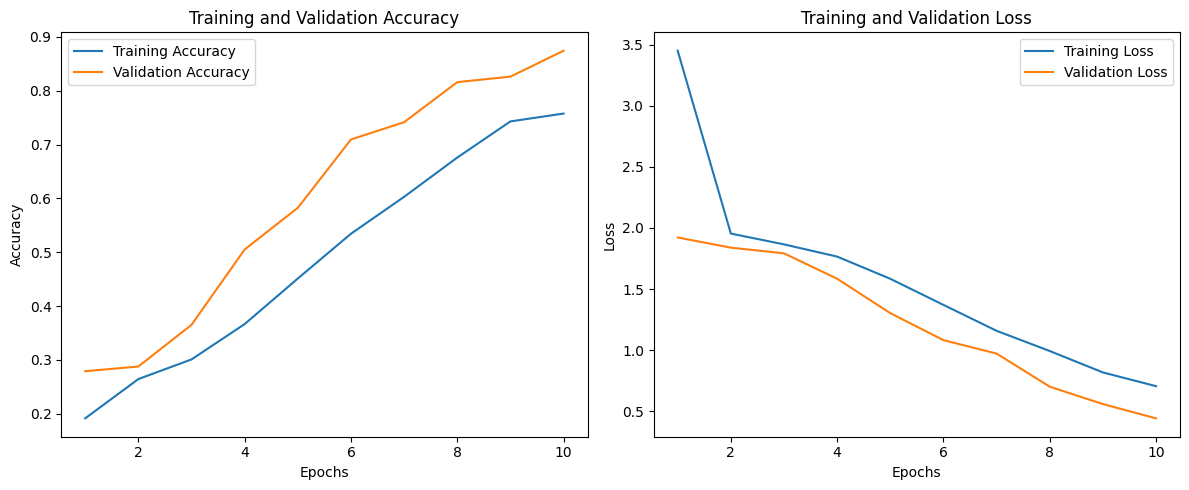

In [33]:
# Extract accuracy and loss from the history object
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(accuracy) + 1)

# Plot training and validation accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()
